# 22 · Skin revisions, review cycle 1 (post hoc)

**Status: post hoc, requested in review.** This notebook answers points raised in the pre-submission review of 29 October 2026 for the two skin test sets, HIBA and PAD-UFES-20. It reads only frozen prediction and fingerprint files, changes no locked result, and writes aggregates only.

| Section | Review point | What it does |
|---|---|---|
| S1 | 3.1 | Degradation-fingerprint test (H5) re-estimated with a **model bootstrap that keeps repeated draws**, plus a leave-one-model-out range. |
| S2 | 2.4, 5.3 | **Lesion-level** summaries: a lesion is referred if any of its images is referred. Lesions, patients, rescues and newly introduced misses, and modelled death equivalents counted **once per lesion**, against the average and the better member. |
| S3 | 2.1 | **Fixed-anchor training-source comparison**: each system as anchor, paired with the same design of another architecture trained on the same or the other collection; unadjusted, strength-matched and strength-adjusted. |
| S4 | 4.2 | **Patient-disjoint local partner choice** in HIBA, with **lesions** as the selection unit; ranks and referral sets rebuilt on the evaluation images; shares of the strongest-partner and best-possible-partner gains. |
| S5 | 5.4 | **Out-of-sample harm tuning**: patients split in half, referral share chosen on one half and scored on the other (both directions), 50 splits, shares from 0% to 100%, three comparators and the in-sample oracle alongside. |
| S6 | 3.2 | **Full-procedure bootstrap** of the H1 benefit (missed melanoma and missed malignancy against the average member): ranks and referral sets rebuilt in every patient resample. |

**Runtime:** CPU, High-RAM, about 30 to 60 minutes.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, json, itertools, datetime, time, hashlib, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import roc_auc_score
DERM = "/content/drive/MyDrive/stochastic_orthogonality/data/derm"; PR, FP = f"{DERM}/predictions", f"{DERM}/fingerprints"
OUTD = f"{DERM}/revisions_c1"; os.makedirs(OUTD, exist_ok=True); OUT_JSON = f"{OUTD}/skin_revisions_c1.json"
assert not os.path.exists(OUT_JSON), "already written; rename the old output deliberately to rerun"
CLASSES = ["MEL", "BCC", "SCC", "AK", "NV", "BKL", "DF", "VASC"]
ARCHS = ["resnet50", "densenet121", "efficientnet_b3", "convnext_t", "vit_b", "vit_b_dinov2"]; SOURCES = ["HAM10000", "BCN20000"]; SEEDS = [0, 1]
MODELS = [(s, a, k) for s in SOURCES for a in ARCHS for k in SEEDS]; VARIANTS = [(s, a) for s in SOURCES for a in ARCHS]
def mname(s, a, k): return f"{s}_{a}_seed{k}"
B, SEED = 1000, 20261030
MEL_D, SCC_D = 1 / 85, 0.006
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
HASHES = {}; SETS = {}
for es in ("HIBA", "PAD"):
    D = pd.read_csv(f"{DERM}/manifest_{es}.csv", dtype={"image_id": str, "lesion_id": str, "patient_id": str}).sort_values("image_id")
    D = D[~D.duplicated("raw_sha256", keep="first") & D.dx.isin(CLASSES)].reset_index(drop=True)
    P = {}
    for m in MODELS:
        fn = f"{PR}/{es}__{mname(*m)}.csv"; HASHES[os.path.basename(fn)] = sha(fn)
        p = pd.read_csv(fn, dtype={"image_id": str}).drop_duplicates("image_id").set_index("image_id").reindex(D.image_id); assert p.p_malignant.notna().all(); P[m] = p.p_malignant.to_numpy()
    lesion = (D.lesion_id.fillna("img_" + D.image_id) if "lesion_id" in D.columns else "img_" + D.image_id).astype(str).to_numpy()
    dx = D.dx.to_numpy(); mal = np.isin(dx, ["MEL", "BCC", "SCC"])
    SETS[es] = {"D": D, "P": P, "dx": dx, "mal": mal, "mel": dx == "MEL", "patient": D.patient_id.astype(str).fillna("none").to_numpy(), "lesion": lesion, "f": round(1.31 * float(mal.mean()), 4)}
    print(f"{es}: {len(D):,} images | {len(set(lesion)):,} lesions | {D.patient_id.nunique():,} patients | melanoma images {int((dx == 'MEL').sum())} | f = {SETS[es]['f']}")
OLD = json.load(open(f"{DERM}/derm_results_v1.json"))

Mounted at /content/drive
HIBA: 1,616 images | 1,246 lesions | 623 patients | melanoma images 253 | f = 0.6088
PAD: 2,283 images | 1,634 lesions | 1,373 patients | melanoma images 52 | f = 0.6203


In [2]:
def refer(s, f):
    r = np.zeros(len(s), bool); r[np.argsort(-s, kind="stable")[:int(round(f * len(s)))]] = True; return r
def rk(s): return rankdata(s) / len(s)
def pairscore(ra, rb): return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
def boot_w(groups, n_boot, seed):
    codes = pd.factorize(groups)[0]; G = codes.max() + 1; rng = np.random.default_rng(seed)
    W = np.empty((n_boot + 1, len(codes)), np.float32); W[0] = 1.0
    for b in range(1, n_boot + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    return W
def ci(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(np.percentile(f, 2.5)) if len(f) else None, float(np.percentile(f, 97.5)) if len(f) else None]
def fmt(t, d=2): return "none" if t is None or None in t else f"{t[0]:.{d}f} ({t[1]:.{d}f} to {t[2]:.{d}f})"
def combos(va, vb):
    if va == vb: return [((*va, i), (*vb, j)) for i in SEEDS for j in SEEDS if i < j]
    return [((*va, i), (*vb, j)) for i in SEEDS for j in SEEDS]
H1_ORDERED = [(va, vb) for va in VARIANTS for vb in VARIANTS if va[1] != vb[1]]          # roster of the locked H1 benefit
ALL66 = list(itertools.combinations(VARIANTS, 2))                                         # roster of notebook 20
REC = {"status": "post hoc analyses requested in review cycle 1 (Astra, 29 Oct 2026); no lock", "bootstrap_resamples": B}
print("ready")

ready


## S1. Degradation fingerprint (H5), corrected model bootstrap
Fingerprints measured on HIBA half A (unlabelled); shared missed malignancies scored on half B, as in the locked analysis. Each resample draws the 24 systems with replacement and keeps multiplicities: a pair of distinct systems enters with weight equal to the product of their draw counts. The leave-one-model-out range and the original set-based interval are shown alongside.

In [3]:
half_a = set(pd.read_csv(f"{FP}/hiba_half_A_patients.csv", dtype={"patient_id": str}).patient_id)
S = SETS["HIBA"]; Bm = ~pd.Series(S["patient"]).isin(half_a).to_numpy(); tgt = S["mal"] & Bm; R = {m: refer(S["P"][m], S["f"]) for m in MODELS}
FPX = {m: dict(np.load(f"{FP}/{mname(*m)}.npz", allow_pickle=True)) for m in MODELS}
GROUPS = {"degradation": ["jpeg_q15", "gamma_dark", "gamma_bright", "noise", "vignette", "blur_r3"], "frequency": ["lowpass_r2", "lowpass_r4", "highpass_r4"], "channel": ["drop_red", "drop_green", "drop_blue"]}
MISS = {m: int((tgt & ~R[m]).sum()) for m in MODELS}; rows = []
for ma, mb in itertools.combinations(MODELS, 2):
    x, y = tgt & ~R[ma], tgt & ~R[mb]; Tn = tgt.sum()
    r = {"a": MODELS.index(ma), "b": MODELS.index(mb), "comiss": ((x & y).sum() / Tn) / ((x.sum() / Tn) * (y.sum() / Tn)) if x.sum() and y.sum() else np.nan,
         "mean_miss": (MISS[ma] + MISS[mb]) / 2, "gap_miss": abs(MISS[ma] - MISS[mb])}
    for g, ks in GROUPS.items(): r[f"sim_{g}"] = float(np.mean([spearmanr(FPX[ma][f"resp_{k}"], FPX[mb][f"resp_{k}"])[0] for k in ks]))
    rows.append(r)
F5 = pd.DataFrame(rows).dropna(subset=["comiss"]).reset_index(drop=True)
def partial(df, p):
    Z_ = np.column_stack([np.ones(len(df)), rankdata(df.mean_miss), rankdata(df.gap_miss)])
    rx = rankdata(df[p]) - Z_ @ np.linalg.lstsq(Z_, rankdata(df[p]), rcond=None)[0]; ry = rankdata(df.comiss) - Z_ @ np.linalg.lstsq(Z_, rankdata(df.comiss), rcond=None)[0]
    return float(np.corrcoef(rx, ry)[0, 1])
rng1 = np.random.default_rng(SEED + 1); draws = [np.bincount(rng1.integers(0, len(MODELS), len(MODELS)), minlength=len(MODELS)) for _ in range(1000)]
S1 = {}
for g in GROUPS:
    p = f"sim_{g}"; obs = partial(F5, p); bs = []
    for c in draws:
        w = c[F5.a.to_numpy()] * c[F5.b.to_numpy()]
        if (w > 0).sum() > 20: bs.append(partial(F5.loc[np.repeat(np.arange(len(F5)), w)], p))
    jk = [partial(F5[(F5.a != i) & (F5.b != i)], p) for i in range(len(MODELS))]
    S1[g] = {"partial_rho_given_strength": round(obs, 3), "model_bootstrap_ci95_with_multiplicity": [round(float(np.percentile(bs, 2.5)), 3), round(float(np.percentile(bs, 97.5)), 3)],
             "leave_one_model_out_range": [round(min(jk), 3), round(max(jk), 3)], "original_set_based_ci95": OLD["H5_fingerprint"][g]["model_bootstrap_ci95"]}
    print(g, S1[g])
S1["degradation_supported_corrected"] = bool(S1["degradation"]["model_bootstrap_ci95_with_multiplicity"][0] > 0)
REC["S1_fingerprint_corrected_bootstrap"] = S1

degradation {'partial_rho_given_strength': 0.512, 'model_bootstrap_ci95_with_multiplicity': [0.312, 0.66], 'leave_one_model_out_range': [0.474, 0.547], 'original_set_based_ci95': [0.3696, 0.6347]}
frequency {'partial_rho_given_strength': 0.487, 'model_bootstrap_ci95_with_multiplicity': [0.321, 0.657], 'leave_one_model_out_range': [0.449, 0.533], 'original_set_based_ci95': [0.3654, 0.6217]}
channel {'partial_rho_given_strength': 0.492, 'model_bootstrap_ci95_with_multiplicity': [0.301, 0.693], 'leave_one_model_out_range': [0.455, 0.55], 'original_set_based_ci95': [0.3356, 0.6553]}


## S2. Lesion-level summaries
A lesion is referred if any of its images is referred, and a malignant lesion (or melanoma) is missed if none of its images is referred. Two rosters: the locked H1 roster (ordered pairs of different architecture, averaged over both orders) against the average member, and all 66 variant pairs (notebook 20) against the average and the better member. Counts are per 10,000 lesions, with rescues (missed by the first system, caught by the pair) and newly introduced misses (caught by the first, missed by the pair) separately. Modelled death equivalents are counted **once per lesion**: melanoma 1/85 (average case) or 1 (worst case), squamous cell carcinoma 0.006. Intervals resample patients.

In [4]:
S2 = {}
for es, S in SETS.items():
    t0 = time.time(); les = pd.factorize(S["lesion"])[0]; nl = les.max() + 1
    les_pat = pd.Series(S["patient"]).groupby(les).first().reindex(range(nl)).to_numpy()
    W = boot_w(les_pat, B, SEED + 2); Wt = W.sum(1, dtype=np.float64)
    def L(v): return np.bincount(les, weights=v.astype(float), minlength=nl) > 0
    ldx = pd.Series(S["dx"]).groupby(les).agg(lambda x: x.value_counts().index[0]).reindex(range(nl)).to_numpy()
    lmel, lmal, lscc = ldx == "MEL", np.isin(ldx, ["MEL", "BCC", "SCC"]), ldx == "SCC"
    harm = {"melanoma": lmel.astype(float), "malignancy": lmal.astype(float), "death_eq_average": MEL_D * lmel + SCC_D * lscc, "death_eq_worst": 1.0 * lmel + SCC_D * lscc}
    own = {m: L(refer(S["P"][m], S["f"])) for m in MODELS}; K = {m: rk(S["P"][m]) for m in MODELS}
    out = {"images": int(len(S["dx"])), "lesions": int(nl), "patients": int(len(set(S["patient"]))), "melanoma_lesions": int(lmel.sum()), "malignant_lesions": int(lmal.sum()),
           "melanoma_images": int(S["mel"].sum())}
    for roster, pairs_ in (("H1_different_architecture", None), ("all_66_variant_pairs", ALL66)):
        acc = {h: {k: np.zeros(B + 1) for k in ("first", "pair", "better", "rescued", "new")} for h in harm}; cnt = cntp = 0
        units = [(ka, kb) for va, vb in (H1_ORDERED if pairs_ is None else pairs_) for ka, kb in combos(va, vb)]
        if pairs_ is None: units = [(ka, kb) for ka, kb in units if ka < kb]                   # each unordered pair once; both orders below
        for ka, kb in units:
            ep = L(refer(pairscore(K[ka], K[kb]), S["f"])); cntp += 1
            for h, hv in harm.items():
                pm = W @ (hv * ~ep).astype(np.float32); ma_ = W @ (hv * ~own[ka]).astype(np.float32); mb_ = W @ (hv * ~own[kb]).astype(np.float32)
                acc[h]["better"] += np.where(ma_ <= mb_, ma_, mb_); acc[h]["pair"] += pm; acc[h]["first"] += 0.5 * (ma_ + mb_)
                for x in (ka, kb):
                    acc[h]["rescued"] += 0.5 * (W @ (hv * (~own[x] & ep)).astype(np.float32)); acc[h]["new"] += 0.5 * (W @ (hv * (own[x] & ~ep)).astype(np.float32))
        res = {}
        for h in harm:
            a_ = {k: v / cntp for k, v in acc[h].items()}
            res[h] = {"vs_average_member_per_10k_lesions": ci((a_["first"] - a_["pair"]) / Wt * 1e4), "vs_better_member_per_10k_lesions": ci((a_["better"] - a_["pair"]) / Wt * 1e4),
                      "relative_vs_average_member": ci((a_["first"] - a_["pair"]) / a_["first"]), "rescued_per_10k_lesions": ci(a_["rescued"] / Wt * 1e4), "newly_missed_per_10k_lesions": ci(a_["new"] / Wt * 1e4)}
        res["pair_combinations"] = cntp; out[roster] = res
    S2[es] = out
    print(f"\n{es} ({time.time() - t0:.0f}s): {out['lesions']} lesions, {out['melanoma_lesions']} melanoma lesions from {out['melanoma_images']} melanoma images")
    for roster in ("H1_different_architecture", "all_66_variant_pairs"):
        for h in harm: print(f"  {roster:26s} {h:18s} vs average {fmt(out[roster][h]['vs_average_member_per_10k_lesions'], 3)} | vs better {fmt(out[roster][h]['vs_better_member_per_10k_lesions'], 3)} | relative {fmt(out[roster][h]['relative_vs_average_member'], 3)} | rescued {fmt(out[roster][h]['rescued_per_10k_lesions'], 2)} | new {fmt(out[roster][h]['newly_missed_per_10k_lesions'], 2)}")
REC["S2_lesion_level"] = S2


HIBA (6s): 1246 lesions, 172 melanoma lesions from 253 melanoma images
  H1_different_architecture  melanoma           vs average 16.553 (6.447 to 27.625) | vs better -4.983 (-22.451 to 1.128) | relative 0.089 (0.032 to 0.159) | rescued 64.49 (47.74 to 84.00) | new 47.94 (34.86 to 64.51)
  H1_different_architecture  malignancy         vs average 49.124 (33.885 to 66.094) | vs better 17.723 (-1.637 to 27.551) | relative 0.186 (0.130 to 0.256) | rescued 120.27 (95.64 to 149.47) | new 71.14 (55.08 to 91.01)
  H1_different_architecture  death_eq_average   vs average 0.278 (0.153 to 0.421) | vs better 0.024 (-0.185 to 0.110) | relative 0.115 (0.061 to 0.181) | rescued 0.92 (0.70 to 1.17) | new 0.64 (0.48 to 0.84)
  H1_different_architecture  death_eq_worst     vs average 16.636 (6.533 to 27.746) | vs better -4.895 (-22.375 to 1.209) | relative 0.090 (0.032 to 0.159) | rescued 64.65 (47.93 to 84.12) | new 48.01 (34.92 to 64.59)
  all_66_variant_pairs       melanoma           vs average 16.3

## S3. Fixed-anchor training-source comparison
For each anchor system (24) and each other architecture, the anchor is paired with that architecture trained on the **same** collection or on the **other** collection (both seeds). Net missed cases avoided relative to the anchor alone, at the locked share f; three views (unadjusted, strength-matched within 10% of standalone misses, adjusted with anchor fixed effects), overall and by anchor collection. Outcomes: melanoma and malignancy in HIBA and PAD-UFES-20 (PAD melanoma is reported but has few events). Intervals resample patients.

In [5]:
S3 = {}
for es, S in SETS.items():
    W = boot_w(S["patient"], B, SEED + 3); Wt = W.sum(1, dtype=np.float64); R = {m: refer(S["P"][m], S["f"]) for m in MODELS}; K = {m: rk(S["P"][m]) for m in MODELS}
    for oname, y in (("melanoma", S["mel"]), ("malignancy", S["mal"])):
        units, vecs = [], []
        for an in MODELS:
            s, a, k = an
            for a2 in ARCHS:
                if a2 == a: continue
                for s2 in SOURCES:
                    for k2 in SEEDS:
                        pt = (s2, a2, k2); e = refer(pairscore(K[an], K[pt]), S["f"])
                        vecs.append((y & ~R[an]).astype(np.int8) - (y & ~e).astype(np.int8))
                        units.append({"anchor": an, "anchor_source": s, "partner_design": a2, "diff_source": int(s2 != s), "partner_miss": int((y & ~R[pt]).sum())})
        U = pd.DataFrame(units); NET = W @ np.stack(vecs).astype(np.float32).T
        AM = np.stack([W @ (y & ~R[u]).astype(np.float32) for u in U.anchor], 1)
        res = {}
        for lab, m in (("all_anchors", np.ones(len(U), bool)), ("HAM10000_anchors", (U.anchor_source == "HAM10000").to_numpy()), ("BCN20000_anchors", (U.anchor_source == "BCN20000").to_numpy())):
            dd_, ss_ = m & (U.diff_source == 1).to_numpy(), m & (U.diff_source == 0).to_numpy()
            nd, ns = NET[:, dd_].mean(1) / Wt * 1e4, NET[:, ss_].mean(1) / Wt * 1e4
            r = {"diff_source_net_per_10k": ci(nd), "same_source_net_per_10k": ci(ns), "diff_minus_same_per_10k": ci(nd - ns),
                 "diff_minus_same_relative": ci(NET[:, dd_].sum(1) / AM[:, dd_].sum(1) - NET[:, ss_].sum(1) / AM[:, ss_].sum(1)),
                 "partner_miss_mean_diff_vs_same": [float(U.partner_miss[dd_].mean()), float(U.partner_miss[ss_].mean())]}
            idd, iss = [], []
            for (an, a2), g in U[m].groupby(["anchor", "partner_design"]):
                gd, gs = g[g.diff_source == 1], g[g.diff_source == 0]; used = set()
                for i_, rr in gd.iterrows():
                    cand = gs[~gs.index.isin(used)]
                    if not len(cand): continue
                    j_ = (cand.partner_miss - rr.partner_miss).abs().idxmin()
                    if abs(cand.partner_miss[j_] - rr.partner_miss) <= 0.10 * max(1, (cand.partner_miss[j_] + rr.partner_miss) / 2): idd.append(i_); iss.append(j_); used.add(j_)
            r["strength_matched_diff_minus_same_per_10k"] = ci((NET[:, idd].mean(1) - NET[:, iss].mean(1)) / Wt * 1e4) if idd else None; r["strength_matched_pairs"] = len(idd)
            Um = U[m].reset_index(drop=True); cols = np.flatnonzero(m)
            X = np.column_stack([Um.diff_source.to_numpy(float), (Um.partner_miss - Um.partner_miss.mean()).to_numpy(float) / 1e2, pd.get_dummies(Um.anchor.astype(str)).to_numpy(float)])
            r["adjusted_diff_source_coef_per_10k"] = ci([float(np.linalg.lstsq(X, NET[b, cols] / Wt[b] * 1e4, rcond=None)[0][0]) for b in range(B + 1)])
            res[lab] = r
        S3[f"{es}_{oname}"] = res
        print(f"\n=== {es} {oname} ===")
        for lab, r in res.items():
            print(f"{lab:18s} diff {fmt(r['diff_source_net_per_10k'])} | same {fmt(r['same_source_net_per_10k'])} | diff-same {fmt(r['diff_minus_same_per_10k'])} | matched {fmt(r['strength_matched_diff_minus_same_per_10k'])} (n={r['strength_matched_pairs']}) | adjusted {fmt(r['adjusted_diff_source_coef_per_10k'])} | partner misses {r['partner_miss_mean_diff_vs_same'][0]:.0f}/{r['partner_miss_mean_diff_vs_same'][1]:.0f}")
REC["S3_fixed_anchor_source"] = S3


=== HIBA melanoma ===
all_anchors        diff 16.86 (3.60 to 31.21) | same 13.87 (2.95 to 25.15) | diff-same 2.99 (-6.24 to 12.83) | matched 3.28 (-7.09 to 13.69) (n=100) | adjusted 2.99 (-6.24 to 12.83) | partner misses 37/37
HAM10000_anchors   diff 22.54 (2.52 to 44.46) | same 15.57 (1.58 to 29.54) | diff-same 6.96 (-14.16 to 29.00) | matched 11.63 (-11.83 to 36.46) (n=50) | adjusted 2.27 (-19.83 to 24.12) | partner misses 36/38
BCN20000_anchors   diff 11.19 (-11.25 to 34.17) | same 12.17 (-4.66 to 27.83) | diff-same -0.98 (-25.48 to 23.99) | matched -5.07 (-33.36 to 24.27) (n=50) | adjusted 4.06 (-20.77 to 30.61) | partner misses 38/36

=== HIBA malignancy ===
all_anchors        diff 87.10 (64.28 to 111.96) | same 60.75 (41.66 to 80.47) | diff-same 26.35 (10.35 to 44.35) | matched 19.39 (2.47 to 38.29) (n=150) | adjusted 26.35 (10.35 to 44.35) | partner misses 72/72
HAM10000_anchors   diff 72.14 (36.54 to 110.42) | same 73.43 (50.95 to 96.98) | diff-same -1.29 (-32.55 to 30.44) | m

## S4. Patient-disjoint local partner choice (HIBA, melanoma)
As in the locked H6: one seed per variant (12 systems, as a site would see one product each), candidates of a different architecture. A draw takes patients with a melanoma lesion in random order until k melanoma **lesions** are available and patients without melanoma until k other lesions are available; one image per lesion forms the calibration sample. Every image of every drawn patient is then excluded, and ranks and referral sets are rebuilt on the remaining images. Outcomes as in notebook 21b R5.

In [6]:
S = SETS["HIBA"]; M = [m for m in MODELS if m[2] == 0]; elig = {a: [b for b in M if b[1] != a[1]] for a in M}
upairs = sorted({tuple(sorted((a, b))) for a in M for b in elig[a]})
pid = pd.factorize(S["patient"])[0]; les = pd.factorize(S["lesion"])[0]; mel = S["mel"]
mel_pat = np.unique(pid[mel]); non_pat = np.setdiff1d(np.unique(pid), mel_pat); RNG4 = np.random.default_rng(SEED + 4); S4 = {}
for k in (25, 50):
    out = {r: [] for r in ("enriched_auc", "random", "true_strongest", "oracle")}; npat_ = []
    for _ in range(200):
        cm, nles = [], set()
        for p_ in RNG4.permutation(mel_pat):
            cm.append(p_); nles |= set(les[mel & (pid == p_)])
            if len(nles) >= k: break
        cn, nles2 = [], set()
        for p_ in RNG4.permutation(non_pat):
            cn.append(p_); nles2 |= set(les[pid == p_])
            if len(nles2) >= k: break
        pick_img = lambda L_, mask: np.array([RNG4.choice(np.flatnonzero(mask & (les == l))) for l in L_])
        si = pick_img(list(nles)[:k], mel); ni = pick_img(list(nles2)[:k], np.ones(len(mel), bool))
        cal = np.r_[si, ni]; ycal = np.r_[np.ones(len(si)), np.zeros(len(ni))]; ev = ~np.isin(pid, np.r_[cm, cn]); se = mel[ev]; npat_.append(len(cm))
        auc = {b: roc_auc_score(ycal, S["P"][b][cal]) for b in M}
        Rv = {m: refer(S["P"][m][ev], S["f"]) for m in M}; Kv = {m: rk(S["P"][m][ev]) for m in M}; am = {m: int((se & ~Rv[m]).sum()) for m in M}
        em = {pq: int((se & ~refer(pairscore(Kv[pq[0]], Kv[pq[1]]), S["f"])).sum()) for pq in upairs}; vals = {r: [] for r in out}
        for a in M:
            sc = {b: am[a] - em[tuple(sorted((a, b)))] for b in elig[a]}
            vals["random"].append(np.mean(list(sc.values()))); vals["oracle"].append(max(sc.values())); vals["true_strongest"].append(sc[min(elig[a], key=lambda b: am[b])]); vals["enriched_auc"].append(sc[max(elig[a], key=lambda b: auc[b])])
        for r in out: out[r].append(np.mean(vals[r]))
    mu = {r: float(np.mean(v)) for r, v in out.items()}
    S4[k] = {"share_of_strongest_partner_gain": round((mu["enriched_auc"] - mu["random"]) / (mu["true_strongest"] - mu["random"]), 3) if mu["true_strongest"] != mu["random"] else None,
             "share_of_oracle_gain": round((mu["enriched_auc"] - mu["random"]) / (mu["oracle"] - mu["random"]), 3) if mu["oracle"] != mu["random"] else None,
             "mean_net_melanoma_rescued": {r: round(v, 2) for r, v in mu.items()}, "mean_patients_with_melanoma_drawn": round(float(np.mean(npat_)), 1),
             "image_split_original": OLD["H6_enriched_partner_choice"].get(str(k))}
    print(k, S4[k])
REC["S4_patient_disjoint_partner_choice"] = S4

25 {'share_of_strongest_partner_gain': 0.28, 'share_of_oracle_gain': 0.107, 'mean_net_melanoma_rescued': {'enriched_auc': 4.04, 'random': 3.45, 'true_strongest': 5.56, 'oracle': 8.94}, 'mean_patients_with_melanoma_drawn': 22.9, 'image_split_original': {'share_of_true_strongest': 0.284, 'mean_net_melanoma_rescued': {'enriched_auc': 4.03, 'random': 3.37, 'true_strongest': 5.69, 'oracle': 9.18}}}
50 {'share_of_strongest_partner_gain': 0.159, 'share_of_oracle_gain': 0.069, 'mean_net_melanoma_rescued': {'enriched_auc': 3.35, 'random': 3.03, 'true_strongest': 5.01, 'oracle': 7.6}, 'mean_patients_with_melanoma_drawn': 45.9, 'image_split_original': {'share_of_true_strongest': 0.404, 'mean_net_melanoma_rescued': {'enriched_auc': 3.88, 'random': 3.05, 'true_strongest': 5.11, 'oracle': 8.4}}}


## S5. Out-of-sample harm tuning
Harm models as in notebook 20: average case (melanoma 1/85 of a death, squamous cell carcinoma 0.006) and worst case (every missed melanoma a death). A benign referral costs 1/K of one death. Roster: all 66 variant pairs × 4 seed combinations. Patients are split in half at random; each arm picks its share (0% to 100%) on one half and is scored at that share on the other, both directions, 50 splits. Comparators: average member, member better on the calibration half, better member on the evaluation half (hindsight); the in-sample oracle is shown alongside. Intervals are percentiles across splits.

  HIBA: split 1 (1s)
  HIBA: split 10 (11s)
HIBA average_case: mean advantage at K = 10 / 316 / 10,000: {'average': [-0.001, 0.56, -0.004], 'better_on_calibration': [0.013, 0.238, 0.027], 'better_hindsight': [-1.195, -0.0, -0.096], 'oracle_better_hindsight': [-0.592, 0.098, -0.004], 'oracle_average': [0.102, 0.583, 0.026]}
HIBA worst_case: mean advantage at K = 10 / 316 / 10,000: {'average': [28.473, 0.077, -2.248], 'better_on_calibration': [15.256, 4.2, 2.746], 'better_hindsight': [-1.276, -7.953, -9.601], 'oracle_better_hindsight': [2.998, -0.278, -0.005], 'oracle_average': [25.616, 0.693, 0.026]}
  PAD: split 1 (1s)
  PAD: split 10 (12s)
PAD average_case: mean advantage at K = 10 / 316 / 10,000: {'average': [-0.041, 0.021, -0.008], 'better_on_calibration': [0.179, 0.022, 0.022], 'better_hindsight': [-0.274, -0.13, -0.053], 'oracle_better_hindsight': [-0.008, -0.089, -0.002], 'oracle_average': [0.008, 0.04, 0.006]}
PAD worst_case: mean advantage at K = 10 / 316 / 10,000: {'average': 

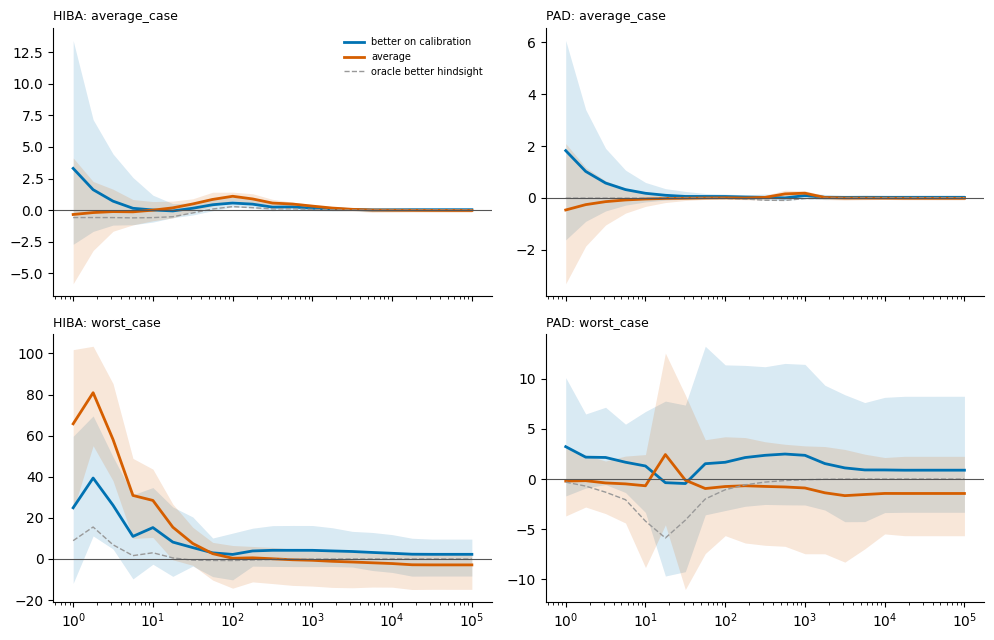

In [7]:
VOLS6 = np.round(np.arange(0, 1.0001, 0.01), 2); KS6 = np.round(np.geomspace(1, 1e5, 21), 2); NS6 = 50
def cost_curves(score, hv, fp):
    n = len(score); o = np.argsort(-score, kind="stable"); kp = np.round(VOLS6 * n).astype(int)
    ch = np.r_[0, np.cumsum(hv[o])]; cf = np.r_[0, np.cumsum(fp[o])]
    return ((ch[-1] - ch[kp])[:, None] + cf[kp][:, None] / KS6[None, :]) / n * 1e4
S5 = {}
for es, S in SETS.items():
    t0 = time.time(); codes = pd.factorize(S["patient"])[0]; G = codes.max() + 1; rng = np.random.default_rng(SEED + 5)
    H = {"average_case": MEL_D * S["mel"] + SCC_D * (S["dx"] == "SCC"), "worst_case": 1.0 * S["mel"] + SCC_D * (S["dx"] == "SCC")}; fp = (~S["mal"]).astype(float)
    res = {h: {c: [] for c in ("average", "better_on_calibration", "better_hindsight", "oracle_better_hindsight", "oracle_average")} for h in H}; bnd = {h: [] for h in H}
    for s in range(NS6):
        half = rng.permutation(G) < G // 2; hm = half[codes]
        for cm_, em_ in ((hm, ~hm), (~hm, hm)):
            kc = {m: rk(S["P"][m][cm_]) for m in MODELS}; ke = {m: rk(S["P"][m][em_]) for m in MODELS}
            for h, hv in H.items():
                Cc = {m: cost_curves(kc[m], hv[cm_], fp[cm_]) for m in MODELS}; Ce = {m: cost_curves(ke[m], hv[em_], fp[em_]) for m in MODELS}
                acc = {c: [] for c in res[h]}; bb = []
                for va, vb in ALL66:
                    for ma, mb in combos(va, vb):
                        pc = cost_curves(pairscore(kc[ma], kc[mb]), hv[cm_], fp[cm_]); pe = cost_curves(pairscore(ke[ma], ke[mb]), hv[em_], fp[em_])
                        ia, ib, ip = np.argmin(Cc[ma], 0), np.argmin(Cc[mb], 0), np.argmin(pc, 0); ar = np.arange(len(KS6))
                        ea, eb, ep = Ce[ma][ia, ar], Ce[mb][ib, ar], pe[ip, ar]
                        acc["average"].append(0.5 * (ea + eb) - ep); acc["better_hindsight"].append(np.minimum(ea, eb) - ep)
                        acc["better_on_calibration"].append(np.where(Cc[ma].min(0) <= Cc[mb].min(0), ea, eb) - ep)
                        acc["oracle_better_hindsight"].append(np.minimum(Ce[ma].min(0), Ce[mb].min(0)) - pe.min(0)); acc["oracle_average"].append(0.5 * (Ce[ma].min(0) + Ce[mb].min(0)) - pe.min(0))
                        bb.append(np.mean([np.isin(x, (0, len(VOLS6) - 1)) for x in (ia, ib, ip)], 0))
                for c in acc: res[h][c].append(np.mean(acc[c], 0))
                bnd[h].append(np.mean(bb, 0))
        if s in (0, 9): print(f"  {es}: split {s + 1} ({time.time() - t0:.0f}s)")
    out = {}
    for h in H:
        out[h] = {"K": KS6.tolist(), "share_of_arms_at_0_or_100pct": np.mean(bnd[h], 0).tolist()}
        for c, L_ in res[h].items():
            A_ = np.array(L_); out[h][c] = {"mean": A_.mean(0).tolist(), "p2.5": np.percentile(A_, 2.5, 0).tolist(), "p97.5": np.percentile(A_, 97.5, 0).tolist()}
        print(f"{es} {h}: mean advantage at K = 10 / 316 / 10,000:", {c: [round(float(np.interp(np.log(kk), np.log(KS6), out[h][c]["mean"])), 3) for kk in (10, 316, 10000)] for c in res[h]})
    S5[es] = out
REC["S5_out_of_sample_harm_tuning"] = S5
fig, ax = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for j, es in enumerate(SETS):
    for r_, h in enumerate(("average_case", "worst_case")):
        x = ax[r_][j]; o = S5[es][h]
        for c, col in (("better_on_calibration", "#0072B2"), ("average", "#D55E00"), ("oracle_better_hindsight", "#999999")):
            x.plot(KS6, o[c]["mean"], color=col, lw=2 if c != "oracle_better_hindsight" else 1, ls="-" if c != "oracle_better_hindsight" else "--", label=c.replace("_", " "))
            if c != "oracle_better_hindsight": x.fill_between(KS6, o[c]["p2.5"], o[c]["p97.5"], color=col, alpha=0.15, lw=0)
        x.axhline(0, color="#555", lw=0.8); x.set_xscale("log"); x.set_title(f"{es}: {h}", loc="left", fontsize=9); [x.spines[s].set_visible(False) for s in ("top", "right")]
ax[0][0].legend(fontsize=7, frameon=False); fig.tight_layout(); fig.savefig(f"{OUTD}/skin_oos_tuning_c1.png", dpi=180); plt.show()

## S6. Full-procedure bootstrap of the H1 benefit
Each resample draws patients with replacement (every image of a drawn patient, as many times as drawn), rebuilds every system's ranks and top-f referral set, and every pair's maximum-rank referral set, then recomputes the pooled relative reduction in missed melanoma and missed malignancy against the average member over the locked roster (ordered pairs of different architecture). The locked estimates are printed alongside.

In [8]:
def h1_stat(dx, P, f):
    mel, mal = dx == "MEL", np.isin(dx, ["MEL", "BCC", "SCC"]); R = {m: refer(p, f) for m, p in P.items()}; K = {m: rk(p) for m, p in P.items()}
    anc = {"mel": 0, "mal": 0}; ens = {"mel": 0, "mal": 0}
    for va, vb in H1_ORDERED:
        for ka, kb in combos(va, vb):
            e = refer(pairscore(K[ka], K[kb]), f)
            for t, y in (("mel", mel), ("mal", mal)): anc[t] += (y & ~R[ka]).sum(); ens[t] += (y & ~e).sum()
    return {t: (anc[t] - ens[t]) / anc[t] if anc[t] else np.nan for t in anc}
S6 = {}
for es, S in SETS.items():
    t0 = time.time(); codes = pd.factorize(S["patient"])[0]; G = codes.max() + 1; members = [np.flatnonzero(codes == g) for g in range(G)]; rng = np.random.default_rng(SEED + 6)
    obs = h1_stat(S["dx"], S["P"], S["f"]); bs = []
    for b in range(1000):
        idx = np.concatenate([members[g] for g in rng.integers(0, G, G)]); bs.append(h1_stat(S["dx"][idx], {m: p[idx] for m, p in S["P"].items()}, S["f"]))
    S6[es] = {t: {"estimate": float(obs[t]), "full_procedure_ci95": [float(np.nanpercentile([x[t] for x in bs], 2.5)), float(np.nanpercentile([x[t] for x in bs], 97.5))],
                  "locked": OLD["H1_benefit"][f"{es}_f"][t]} for t in obs}
    print(es, f"({time.time() - t0:.0f}s)", json.dumps(S6[es]))
REC["S6_full_procedure_bootstrap_H1"] = S6

HIBA (112s) {"mel": {"estimate": 0.06788154897494306, "full_procedure_ci95": [0.021831936433253932, 0.18618668745833117], "locked": {"relative_reduction_matched_volume": 0.0682, "ci95": [0.0209, 0.1217], "deployed_misses_per_pair": 36.58, "union_rescue_share": 0.5527}}, "mal": {"estimate": 0.16707459207459208, "full_procedure_ci95": [0.0966597995545657, 0.28972912495751735], "locked": {"relative_reduction_matched_volume": 0.1671, "ci95": [0.1215, 0.2161], "deployed_misses_per_pair": 71.5, "union_rescue_share": 0.6636}}}
PAD (156s) {"mel": {"estimate": 0.04352, "full_procedure_ci95": [-0.01920348413506515, 0.10817741569164717], "locked": {"relative_reduction_matched_volume": 0.0435, "ci95": [-0.0127, 0.1133], "deployed_misses_per_pair": 26.04, "union_rescue_share": 0.3482}}, "mal": {"estimate": 0.09917136812411848, "full_procedure_ci95": [0.07626565638233401, 0.12118344421949735], "locked": {"relative_reduction_matched_volume": 0.0989, "ci95": [0.0744, 0.1236], "deployed_misses_per_pair

## Write the results record

In [9]:
REC["written_utc"] = datetime.datetime.now(datetime.timezone.utc).isoformat(); REC["input_sha256"] = HASHES
def tolist(x): return {str(k): tolist(v) for k, v in x.items()} if isinstance(x, dict) else ([tolist(v) for v in x] if isinstance(x, (list, tuple)) else (x.tolist() if isinstance(x, np.ndarray) else x))
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
drive.flush_and_unmount(); drive.mount("/content/drive"); print("written", OUT_JSON)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/derm/revisions_c1/skin_revisions_c1.json
